# Proyecto Integrador de Ciencia de Datos
## Fase 3, actividad 5: Modelado avanzado y ajuste de hiperparámetros

**Universidad de La Salle**, Maestría en Inteligencia Artificial
**Asignatura:** Ciencia de Datos (2026-2). **Docente:** Fabián Camilo Castro Riveros
**Estudiante:** Martín Gracia Socha (trabajo individual)
**Conjunto de datos:** METABRIC

### Contenido
1. Configuración y protocolo de evaluación
2. Regresión del NPI: Ridge, ElasticNet (incluye Lasso), Random Forest y XGBoost
3. Clasificación del subtipo PAM50: regresión logística regularizada, SVM, Random Forest y XGBoost
4. Clustering de pacientes: K-Means, clustering jerárquico aglomerativo y DBSCAN
5. Modelos guardados y conclusiones

El perceptrón multicapa (MLP) en PyTorch está en el cuaderno `05_MLP_PyTorch.ipynb`. La evaluación final en el conjunto de prueba, la comparación estadística y la interpretabilidad (SHAP) corresponden a la actividad 6.

## 1. Configuración y protocolo de evaluación

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

# --- Entorno: en Google Colab se clona el repositorio y se instalan dependencias faltantes ---
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/MartinGia/metabric-proyecto-integrador.git"
if IN_COLAB:
    # En Colab se clona el repositorio (datos, código y modelos) y se instalan las librerías que Colab no trae.
    import os, subprocess, importlib.util
    repo_dir = Path("/content/metabric-proyecto-integrador")
    if not (repo_dir / "src" / "config.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "notebooks")
    for pkg, module in [("imbalanced-learn", "imblearn"), ("xgboost", "xgboost"), ("shap", "shap")]:
        if importlib.util.find_spec(module) is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

def find_project_root():
    for c in [Path.cwd(), *Path.cwd().parents]:
        if (c / "src" / "config.py").exists():
            return c
    raise FileNotFoundError("No se encontró la carpeta del proyecto (debe contener src/config.py). "
                            "Abra el notebook desde la carpeta notebooks/ del repositorio.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

import joblib
from tempfile import mkdtemp
from shutil import rmtree
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, StratifiedKFold
from sklearn.linear_model import Ridge, ElasticNet, LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors, NearestCentroid
from sklearn.metrics import (silhouette_score, silhouette_samples, adjusted_rand_score,
                             normalized_mutual_info_score, confusion_matrix)
from sklearn.utils.class_weight import compute_sample_weight
from scipy.cluster.hierarchy import linkage, dendrogram
from xgboost import XGBRegressor, XGBClassifier

# --- Localización de la raíz del proyecto (carpeta que contiene src/config.py) ---
ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config
from src.preprocessing import build_preprocessor, all_columns
from src.modeling import load_processed, task_data, regression_metrics, classification_metrics, CLASS_ORDER

config.ensure_dirs()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
SEED = config.RANDOM_STATE
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    plt.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

print("Carpeta del proyecto:", ROOT.name)

Carpeta del proyecto: repo


**Protocolo.** Para que la comparación sea justa y no haya fuga de información:

* Cada modelo es un `Pipeline` (preprocesador de la actividad 3 + estimador). En la búsqueda de hiperparámetros, el preprocesador se reajusta dentro de cada pliegue.
* Los hiperparámetros se eligen con **validación cruzada de 5 pliegues** sobre entrenamiento (`GridSearchCV` cuando la rejilla es pequeña y `RandomizedSearchCV` cuando el espacio es grande), con la misma semilla para todos los modelos.
* La métrica de selección es **RMSE** en regresión y **F1 macro** en clasificación, igual que en el modelo base.
* El conjunto de **validación** se usa para comparar los modelos ya ajustados. El de **prueba** no se toca en esta actividad.
* El sobreajuste se mide como la brecha entre la métrica de entrenamiento y la de validación cruzada del mejor candidato.

In [2]:
df, FS = load_processed()
reg_df, y_reg = task_data(df, "regression")
clf_df, y_clf = task_data(df, "classification")
reg_cols, clf_cols = all_columns(FS["regression"]), all_columns(FS["classification"])

Xr_tr, yr_tr = reg_df.loc[reg_df.split == "train", reg_cols], reg_df.loc[reg_df.split == "train", y_reg]
Xr_va, yr_va = reg_df.loc[reg_df.split == "val", reg_cols], reg_df.loc[reg_df.split == "val", y_reg]
Xc_tr, yc_tr = clf_df.loc[clf_df.split == "train", clf_cols], clf_df.loc[clf_df.split == "train", y_clf]
Xc_va, yc_va = clf_df.loc[clf_df.split == "val", clf_cols], clf_df.loc[clf_df.split == "val", y_clf]

le = LabelEncoder().fit(CLASS_ORDER)          # XGBoost necesita etiquetas enteras
yc_tr_enc, yc_va_enc = le.transform(yc_tr), le.transform(yc_va)

baseline = json.load(open(config.METRICS_DIR / "baseline_thresholds.json", encoding="utf-8"))
print(f"Regresión: train {Xr_tr.shape}, val {Xr_va.shape} | Clasificación: train {Xc_tr.shape}, val {Xc_va.shape}")
print("Umbrales del modelo base:", json.dumps(baseline, ensure_ascii=False)[:300], "...")

CACHE = mkdtemp()  # caché del preprocesador entre combinaciones de hiperparámetros (mismos pliegues)
cv_reg = KFold(5, shuffle=True, random_state=SEED)
cv_clf = StratifiedKFold(5, shuffle=True, random_state=SEED)

Regresión: train (1285, 572), val (280, 572) | Clasificación: train (1328, 576), val (284, 576)
Umbrales del modelo base: {"regression": {"model": "LinearRegression(proliferation_score)", "RMSE_cv": 0.9951295095546705, "R2_cv": 0.15259689256454587, "RMSE_val": 1.0253020597773863, "R2_val": 0.12058224640058457}, "classification": {"model": "LogisticRegression(all features)", "imbalance": "class_weight = balanced", "F1_m ...


In [3]:
def search(name, estimator, blocks, grid, X, y, task, n_iter=None, fit_params=None):
    """Búsqueda de hiperparámetros con CV y resumen del mejor candidato."""
    pipe = Pipeline([("pre", build_preprocessor(blocks)), ("model", estimator)], memory=CACHE)
    if task == "regression":
        scoring = {"R2": "r2", "RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error"}
        refit, cv = "RMSE", cv_reg
    else:
        scoring = {"F1_macro": "f1_macro", "Balanced_Accuracy": "balanced_accuracy", "Accuracy": "accuracy"}
        refit, cv = "F1_macro", cv_clf
    common = dict(scoring=scoring, refit=refit, cv=cv, n_jobs=-1, return_train_score=True)
    if n_iter:
        s = RandomizedSearchCV(pipe, grid, n_iter=n_iter, random_state=SEED, **common)
    else:
        s = GridSearchCV(pipe, grid, **common)
    t0 = time.time()
    s.fit(X, y, **(fit_params or {}))
    r, i = s.cv_results_, s.best_index_
    sign = {"RMSE": -1, "MAE": -1}
    summary = {"modelo": name, "candidatos": len(r["params"]), "tiempo_s": round(time.time() - t0, 1)}
    for m in scoring:
        k = sign.get(m, 1)
        summary[f"CV {m}"] = k * r[f"mean_test_{m}"][i]
        summary[f"CV {m} (desv.)"] = r[f"std_test_{m}"][i]
        summary[f"train {m}"] = k * r[f"mean_train_{m}"][i]
    summary["mejores hiperparámetros"] = {k.replace("model__", ""): v for k, v in s.best_params_.items()}
    print(f"{name}: {summary['candidatos']} candidatos × 5 pliegues en {summary['tiempo_s']} s -> {summary['mejores hiperparámetros']}")
    return s.best_estimator_, summary

## 2. Regresión del NPI
Se comparan dos familias, como exige la guía:

* **Lineales regularizados.** **Ridge** (penalización L2) y **ElasticNet**, que combina L1 y L2; con `l1_ratio = 1` equivale a **Lasso**, por lo que la misma rejilla evalúa Lasso. La regularización ataca el sobreajuste extremo que mostró la regresión lineal sin regularizar (R² de CV = −0,63).
* **Ensambles de árboles.** **Random Forest** (*bagging*, reduce varianza) y **XGBoost** (*boosting*, reduce sesgo). Capturan no linealidades e interacciones.

In [4]:
B = FS["regression"]
reg_results, reg_models = [], {}

m, s = search("Ridge", Ridge(), B, {"model__alpha": np.logspace(0, 4.5, 10)}, Xr_tr, yr_tr, "regression")
reg_models["Ridge"], _ = m, reg_results.append(s)

m, s = search("ElasticNet / Lasso", ElasticNet(max_iter=20000, random_state=SEED), B,
              {"model__alpha": [0.01, 0.02, 0.05, 0.1, 0.2, 0.4], "model__l1_ratio": [0.1, 0.3, 0.5, 0.9, 1.0]},
              Xr_tr, yr_tr, "regression")
reg_models["ElasticNet / Lasso"], _ = m, reg_results.append(s)

m, s = search("Random Forest", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1), B,
              {"model__max_features": ["sqrt", 0.1, 0.3], "model__min_samples_leaf": [1, 3, 5, 10],
               "model__max_depth": [None, 8, 16]}, Xr_tr, yr_tr, "regression", n_iter=10)
reg_models["Random Forest"], _ = m, reg_results.append(s)

m, s = search("XGBoost", XGBRegressor(random_state=SEED, n_jobs=1, tree_method="hist"), B,
              {"model__n_estimators": [200, 400, 700], "model__learning_rate": [0.02, 0.05, 0.1],
               "model__max_depth": [2, 3, 4], "model__subsample": [0.7, 0.9],
               "model__colsample_bytree": [0.2, 0.4], "model__reg_lambda": [1, 5, 20],
               "model__min_child_weight": [1, 5, 10]}, Xr_tr, yr_tr, "regression", n_iter=12)
reg_models["XGBoost"], _ = m, reg_results.append(s)

Ridge: 10 candidatos × 5 pliegues en 4.2 s -> {'alpha': np.float64(3162.2776601683795)}


ElasticNet / Lasso: 30 candidatos × 5 pliegues en 10.7 s -> {'alpha': 0.4, 'l1_ratio': 0.1}


Random Forest: 10 candidatos × 5 pliegues en 195.4 s -> {'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 8}


XGBoost: 12 candidatos × 5 pliegues en 147.3 s -> {'subsample': 0.7, 'reg_lambda': 20, 'n_estimators': 700, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.02, 'colsample_bytree': 0.2}


In [5]:
rows = []
for s in reg_results:
    mdl = reg_models[s["modelo"]]
    va = regression_metrics(yr_va, mdl.predict(Xr_va))
    rows.append({"modelo": s["modelo"],
                 "R2 CV": f"{s['CV R2']:.3f} ± {s['CV R2 (desv.)']:.3f}",
                 "RMSE CV": f"{s['CV RMSE']:.3f} ± {s['CV RMSE (desv.)']:.3f}",
                 "MAE CV": s["CV MAE"], "brecha R2 train-CV": s["train R2"] - s["CV R2"],
                 "R2 val": va["R2"], "RMSE val": va["RMSE"], "MAE val": va["MAE"],
                 "_rmse_cv": s["CV RMSE"]})
rows.append({"modelo": "Modelo base: lineal simple (proliferación)",
             "R2 CV": f"{baseline['regression']['R2_cv']:.3f}", "RMSE CV": f"{baseline['regression']['RMSE_cv']:.3f}",
             "R2 val": baseline["regression"]["R2_val"], "RMSE val": baseline["regression"]["RMSE_val"],
             "_rmse_cv": baseline["regression"]["RMSE_cv"]})
reg_table = pd.DataFrame(rows).set_index("modelo")
display(reg_table.drop(columns="_rmse_cv"))
with pd.option_context("display.max_colwidth", 200):
    display(pd.DataFrame(reg_results).set_index("modelo")[["mejores hiperparámetros", "tiempo_s"]])
# Regla de un error estándar (Hastie et al., 2009): entre los modelos cuyo RMSE de CV está a menos de un
# error estándar del mejor, se prefiere el más simple (menor riesgo de sobreajuste).
SIMPLICITY = ["Ridge", "ElasticNet / Lasso", "Random Forest", "XGBoost"]
res_df = pd.DataFrame(reg_results).set_index("modelo")
best_cv = res_df["CV RMSE"].idxmin()
se = res_df.loc[best_cv, "CV RMSE (desv.)"] / np.sqrt(5)
within = res_df.index[res_df["CV RMSE"] <= res_df.loc[best_cv, "CV RMSE"] + se]
best_reg_name = [m for m in SIMPLICITY if m in within][0]
print(f"Menor RMSE de CV: {best_cv} ({res_df.loc[best_cv, 'CV RMSE']:.3f}); umbral de 1 error estándar: "
      f"{res_df.loc[best_cv, 'CV RMSE'] + se:.3f}")
print("Modelos dentro del umbral:", ", ".join(within))
print("Líder provisional (el más simple dentro del umbral):", best_reg_name,
      "| la selección final se confirma en la actividad 6.")

,R2 CV,RMSE CV,MAE CV,brecha R2 train-CV,R2 val,RMSE val,MAE val
modelo,,,,,,,
Ridge,0.230 ± 0.020,0.949 ± 0.023,0.775,0.125,0.209,0.972,0.782
ElasticNet / Lasso,0.218 ± 0.024,0.956 ± 0.022,0.782,0.102,0.202,0.977,0.785
Random Forest,0.217 ± 0.019,0.956 ± 0.027,0.792,0.549,0.177,0.992,0.806
XGBoost,0.233 ± 0.026,0.947 ± 0.032,0.775,0.580,0.167,0.998,0.789
Modelo base: lineal simple (proliferación),0.153,0.995,NaN,NaN,0.121,1.025,NaN


,mejores hiperparámetros,tiempo_s
modelo,,
Ridge,{'alpha': 3162.2776601683795},4.200
ElasticNet / Lasso,"{'alpha': 0.4, 'l1_ratio': 0.1}",10.700
Random Forest,"{'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 8}",195.400
XGBoost,"{'subsample': 0.7, 'reg_lambda': 20, 'n_estimators': 700, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.02, 'colsample_bytree': 0.2}",147.300


Menor RMSE de CV: XGBoost (0.947); umbral de 1 error estándar: 0.961
Modelos dentro del umbral: Ridge, ElasticNet / Lasso, Random Forest, XGBoost
Líder provisional (el más simple dentro del umbral): Ridge | la selección final se confirma en la actividad 6.


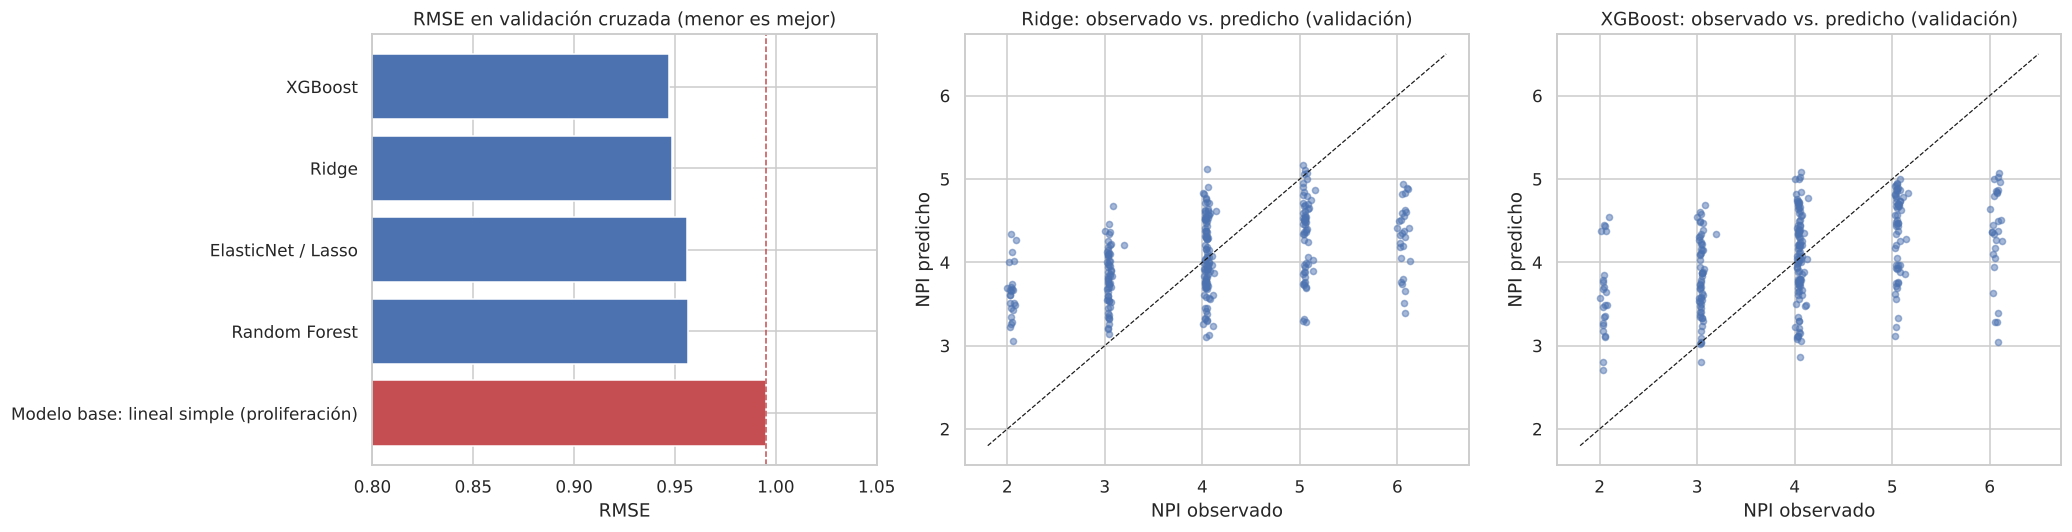

ElasticNet: 76 de 588 coeficientes distintos de cero (selección de variables por L1).
Coeficientes de mayor magnitud:


,genes__ncoa3,genes__gsk3b,genes__aurka,genes__runx1,genes__diras3,genes__nr2f1,genes__aph1b,genes__stat5b,clinical__proliferation_score,genes__bcl2,genes__igf1r,genes__cdk1
coeficiente,0.078,0.066,0.063,-0.051,-0.045,0.041,-0.040,-0.040,0.040,-0.039,-0.034,0.033


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
plot = reg_table["_rmse_cv"].sort_values()
colors = ["#C44E52" if "base" in i else "#4C72B0" for i in plot.index]
axes[0].barh(plot.index, plot.values, color=colors)
axes[0].axvline(baseline["regression"]["RMSE_cv"], color="#C44E52", ls="--", lw=1)
axes[0].set(title="RMSE en validación cruzada (menor es mejor)", xlabel="RMSE", xlim=(0.8, 1.05))
axes[0].invert_yaxis()
for ax, name in zip(axes[1:], list(dict.fromkeys([best_reg_name, best_cv, "XGBoost", "Ridge"]))[:2]):
    pred = reg_models[name].predict(Xr_va)
    ax.scatter(yr_va, pred, alpha=.5, s=16)
    ax.plot([1.8, 6.5], [1.8, 6.5], "k--", lw=.8)
    ax.set(title=f"{name}: observado vs. predicho (validación)", xlabel="NPI observado", ylabel="NPI predicho")
plt.tight_layout()
savefig("21_regresion_modelos")
plt.show()

enet = reg_models["ElasticNet / Lasso"]
coefs = pd.Series(enet.named_steps["model"].coef_, index=enet.named_steps["pre"].get_feature_names_out())
print(f"ElasticNet: {(coefs != 0).sum()} de {len(coefs)} coeficientes distintos de cero (selección de variables por L1).")
print("Coeficientes de mayor magnitud:")
display(coefs[coefs != 0].sort_values(key=abs, ascending=False).head(12).rename("coeficiente").to_frame().T)

## 3. Clasificación del subtipo PAM50
La guía pide comparar al menos dos algoritmos entre KNN, árboles, Random Forest, SVM y XGBoost. Se evalúan **SVM**, **Random Forest** y **XGBoost**, además de una **regresión logística regularizada** con C ajustado, que es la versión optimizada del modelo base. Todos usan el tratamiento de desbalance elegido en la actividad 4: `class_weight="balanced"`, o pesos por muestra equivalentes en XGBoost.

In [7]:
B = FS["classification"]
clf_results, clf_models = [], {}

m, s = search("Logística regularizada (L2)", LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED),
              B, {"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}, Xc_tr, yc_tr, "classification")
clf_models["Logística regularizada (L2)"], _ = m, clf_results.append(s)

m, s = search("SVM", SVC(class_weight="balanced", random_state=SEED), B,
              [{"model__kernel": ["rbf"], "model__C": [0.3, 1, 3, 10, 30], "model__gamma": ["scale", 3e-4, 1e-3]},
               {"model__kernel": ["linear"], "model__C": [0.0003, 0.001, 0.003, 0.01]}],
              Xc_tr, yc_tr, "classification")
clf_models["SVM"], _ = m, clf_results.append(s)

m, s = search("Random Forest", RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample",
                                                      random_state=SEED, n_jobs=1), B,
              {"model__max_features": ["sqrt", 0.05, 0.15], "model__min_samples_leaf": [1, 2, 5],
               "model__max_depth": [None, 12, 24]}, Xc_tr, yc_tr, "classification", n_iter=10)
clf_models["Random Forest"], _ = m, clf_results.append(s)

sw = compute_sample_weight("balanced", yc_tr_enc)
m, s = search("XGBoost", XGBClassifier(random_state=SEED, n_jobs=1, tree_method="hist", eval_metric="mlogloss"), B,
              {"model__n_estimators": [200, 400], "model__learning_rate": [0.05, 0.1],
               "model__max_depth": [2, 3, 4], "model__subsample": [0.7, 0.9],
               "model__colsample_bytree": [0.2, 0.4], "model__reg_lambda": [1, 5]},
              Xc_tr, yc_tr_enc, "classification", n_iter=10, fit_params={"model__sample_weight": sw})
clf_models["XGBoost"], _ = m, clf_results.append(s)

Logística regularizada (L2): 7 candidatos × 5 pliegues en 4.7 s -> {'C': 0.01}


SVM: 19 candidatos × 5 pliegues en 30.8 s -> {'C': 3, 'gamma': 0.001, 'kernel': 'rbf'}


Random Forest: 10 candidatos × 5 pliegues en 221.6 s -> {'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 12}


XGBoost: 10 candidatos × 5 pliegues en 266.5 s -> {'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.4}


In [8]:
# El SVM se reajusta con probability=True (calibración de Platt) para poder calcular AUC-ROC
svm_best = clf_models["SVM"]
svm_best.set_params(model__probability=True).fit(Xc_tr, yc_tr)

def predict_labels(name, X):
    p = clf_models[name].predict(X)
    return le.inverse_transform(p) if name == "XGBoost" else p

def predict_proba_ordered(name, X):
    mdl = clf_models[name]
    proba = mdl.predict_proba(X)
    classes = le.classes_ if name == "XGBoost" else mdl.classes_
    return pd.DataFrame(proba, columns=classes)[sorted(CLASS_ORDER)].to_numpy()

rows = []
for s in clf_results:
    name = s["modelo"]
    va = classification_metrics(yc_va, predict_labels(name, Xc_va), predict_proba_ordered(name, Xc_va), sorted(CLASS_ORDER))
    rows.append({"modelo": name,
                 "F1 macro CV": f"{s['CV F1_macro']:.3f} ± {s['CV F1_macro (desv.)']:.3f}",
                 "Bal. Acc. CV": s["CV Balanced_Accuracy"], "brecha F1 train-CV": s["train F1_macro"] - s["CV F1_macro"],
                 "Accuracy val": va["Accuracy"], "Precision val": va["Precision_macro"], "Recall val": va["Recall_macro"],
                 "F1 macro val": va["F1_macro"], "AUC-ROC val": va["AUC_ROC_ovr"], "_f1_cv": s["CV F1_macro"]})
rows.append({"modelo": "Modelo base: logística básica", "F1 macro CV": f"{baseline['classification']['F1_macro_cv']:.3f}",
             "brecha F1 train-CV": 0.302, "F1 macro val": baseline["classification"]["F1_macro_val"],
             "AUC-ROC val": baseline["classification"]["AUC_val"], "_f1_cv": baseline["classification"]["F1_macro_cv"]})
clf_table = pd.DataFrame(rows).set_index("modelo")
display(clf_table.drop(columns="_f1_cv"))
with pd.option_context("display.max_colwidth", 200):
    display(pd.DataFrame(clf_results).set_index("modelo")[["mejores hiperparámetros", "tiempo_s"]])
cres = pd.DataFrame(clf_results).set_index("modelo")
best_cv_c = cres["CV F1_macro"].idxmax()
se_c = cres.loc[best_cv_c, "CV F1_macro (desv.)"] / np.sqrt(5)
within_c = cres.index[cres["CV F1_macro"] >= cres.loc[best_cv_c, "CV F1_macro"] - se_c]
best_clf_name = best_cv_c
print(f"Mayor F1 macro de CV: {best_cv_c} ({cres.loc[best_cv_c, 'CV F1_macro']:.3f}); umbral de 1 error estándar: "
      f"{cres.loc[best_cv_c, 'CV F1_macro'] - se_c:.3f}")
print("Modelos dentro del umbral:", ", ".join(within_c), "| la selección final se hace en la actividad 6.")

,F1 macro CV,Bal. Acc. CV,brecha F1 train-CV,Accuracy val,Precision val,Recall val,F1 macro val,AUC-ROC val
modelo,,,,,,,,
Logística regularizada (L2),0.736 ± 0.017,0.742,0.220,0.771,0.752,0.762,0.756,0.968
SVM,0.741 ± 0.035,0.732,0.245,0.775,0.747,0.731,0.737,0.968
Random Forest,0.722 ± 0.025,0.702,0.269,0.778,0.788,0.723,0.739,0.963
XGBoost,0.746 ± 0.018,0.732,0.254,0.817,0.808,0.772,0.787,0.969
Modelo base: logística básica,0.698,NaN,0.302,NaN,NaN,NaN,0.755,0.959


,mejores hiperparámetros,tiempo_s
modelo,,
Logística regularizada (L2),{'C': 0.01},4.700
SVM,"{'C': 3, 'gamma': 0.001, 'kernel': 'rbf'}",30.800
Random Forest,"{'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 12}",221.600
XGBoost,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.4}",266.500


Mayor F1 macro de CV: XGBoost (0.746); umbral de 1 error estándar: 0.738
Modelos dentro del umbral: SVM, XGBoost | la selección final se hace en la actividad 6.


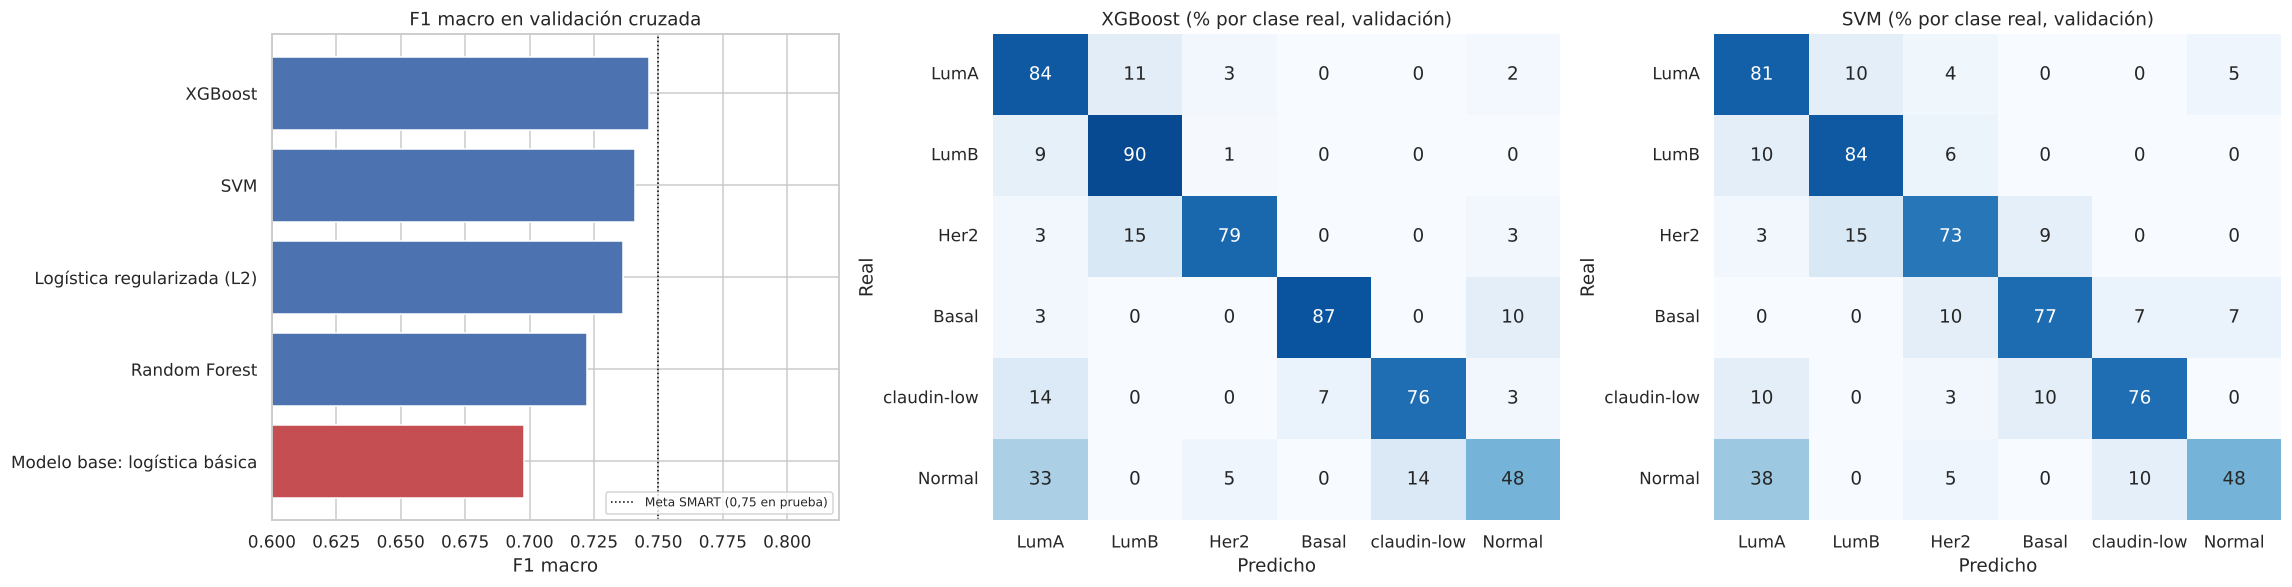

In [9]:
top2 = clf_table.drop(index=clf_table.index[-1])["_f1_cv"].sort_values(ascending=False).index[:2]
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
plot = clf_table["_f1_cv"].sort_values(ascending=False)
axes[0].barh(plot.index, plot.values, color=["#C44E52" if "base" in i else "#4C72B0" for i in plot.index])
axes[0].axvline(0.75, color="black", ls=":", lw=1, label="Meta SMART (0,75 en prueba)")
axes[0].set(title="F1 macro en validación cruzada", xlabel="F1 macro", xlim=(0.6, 0.82))
axes[0].invert_yaxis()
axes[0].legend(fontsize=8, loc="lower right")
for ax, name in zip(axes[1:], top2):
    cm = confusion_matrix(yc_va, predict_labels(name, Xc_va), labels=CLASS_ORDER, normalize="true")
    sns.heatmap(cm * 100, annot=True, fmt=".0f", cmap="Blues", xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER,
                ax=ax, cbar=False, vmin=0, vmax=100)
    ax.set(title=f"{name} (% por clase real, validación)", xlabel="Predicho", ylabel="Real")
plt.tight_layout()
savefig("22_clasificacion_modelos")
plt.show()

## 4. Clustering de pacientes
**Datos.** Se usan los z-scores de expresión de los 489 genes, sin etiquetas clínicas, para descubrir grupos de forma no supervisada. El escalado, el PCA y los algoritmos se ajustan **solo con entrenamiento**; validación y prueba se asignan después al clúster más cercano.

**Reducción de dimensión.** En 489 dimensiones las distancias euclidianas pierden contraste (maldición de la dimensionalidad), lo que perjudica a K-Means y DBSCAN. Por eso se proyecta a las primeras componentes principales; el número de componentes se elige con el **método del codo** sobre la varianza explicada (algoritmo *kneedle*: el punto más alejado de la recta que une los extremos de la curva).

Componentes elegidas por el codo: 10 (varianza explicada acumulada: 35.8 %)


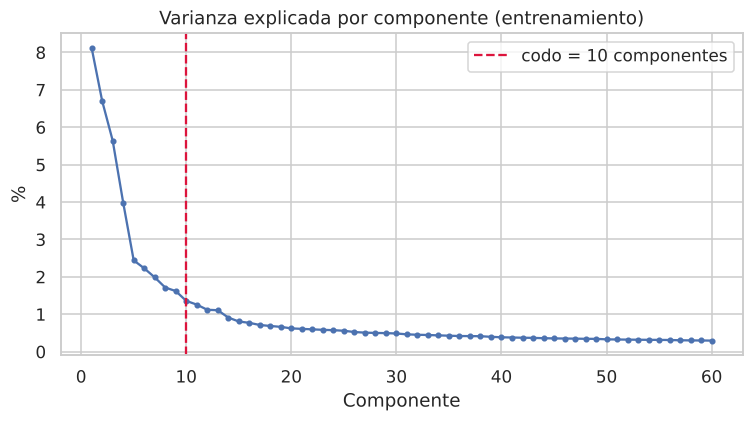

In [10]:
def kneedle(x, y):
    """Índice del codo de una curva decreciente y convexa."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    xn, yn = (x - x.min()) / (x.max() - x.min()), (y - y.min()) / (y.max() - y.min())
    return int(np.argmax((1 - xn) - yn))

genes = FS["clustering"]["genes"]
tr_g = df[df.split == "train"]
scaler_g = StandardScaler().fit(tr_g[genes])
pca_full = PCA(random_state=SEED).fit(scaler_g.transform(tr_g[genes]))
evr = pca_full.explained_variance_ratio_[:60]
N_PC = kneedle(np.arange(1, 61), evr) + 1
print(f"Componentes elegidas por el codo: {N_PC} (varianza explicada acumulada: {100 * evr[:N_PC].sum():.1f} %)")

pca = PCA(n_components=N_PC, random_state=SEED).fit(scaler_g.transform(tr_g[genes]))
Z_all = pca.transform(scaler_g.transform(df[genes]))
is_tr = (df.split == "train").to_numpy()
Z_tr = Z_all[is_tr]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(range(1, 61), 100 * evr, marker="o", ms=3)
ax.axvline(N_PC, color="crimson", ls="--", label=f"codo = {N_PC} componentes")
ax.set(title="Varianza explicada por componente (entrenamiento)", xlabel="Componente", ylabel="%")
ax.legend()
plt.show()

### 4.1 K-Means: número óptimo de clústeres
Se evalúa K de 2 a 10 con dos criterios que exige la guía: el **método del codo** sobre la inercia (suma de distancias cuadradas intraclúster) y el **coeficiente de silueta** (de −1 a 1; valores altos indican clústeres compactos y separados). Además, se mide la correspondencia con los subtipos PAM50 mediante el **Índice de Rand Ajustado (ARI)**, que no interviene en la elección y sirve solo para validar externamente.

,inercia,silueta,ARI vs PAM50
K,,,
2,"201,129.452",0.181,0.251
3,"175,293.485",0.150,0.149
4,"155,254.668",0.158,0.210
5,"144,282.813",0.136,0.183
6,"135,122.566",0.138,0.236
7,"126,903.435",0.144,0.230
8,"121,324.958",0.136,0.239
9,"116,534.006",0.132,0.203
10,"112,544.844",0.131,0.196


K por el codo: 4 | K con mayor silueta: 2


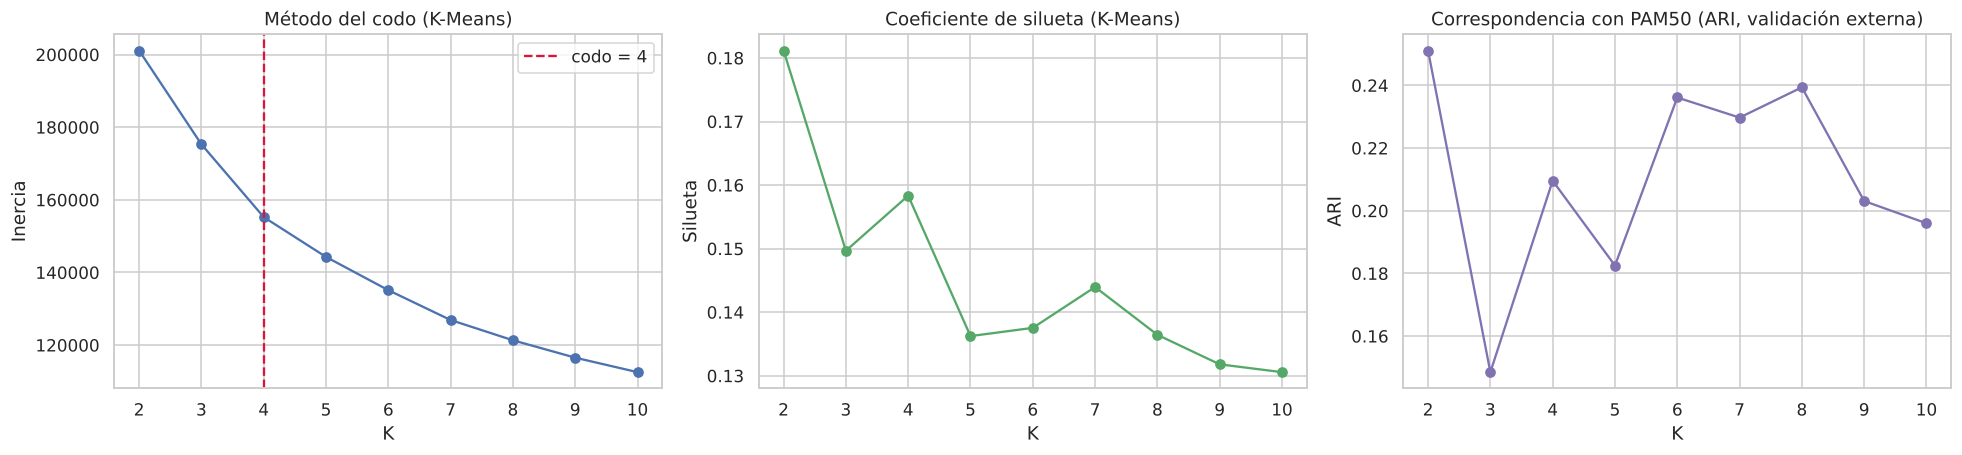

In [11]:
pam_tr = df.loc[is_tr, config.TARGET_CLASSIFICATION].to_numpy()
ks = range(2, 11)
km_rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(Z_tr)
    km_rows.append({"K": k, "inercia": km.inertia_, "silueta": silhouette_score(Z_tr, km.labels_),
                    "ARI vs PAM50": adjusted_rand_score(pam_tr, km.labels_)})
km_eval = pd.DataFrame(km_rows).set_index("K")
k_elbow = ks[kneedle(list(ks), km_eval["inercia"])]
k_sil = km_eval["silueta"].idxmax()
display(km_eval)
print(f"K por el codo: {k_elbow} | K con mayor silueta: {k_sil}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
axes[0].plot(km_eval.index, km_eval["inercia"], marker="o")
axes[0].axvline(k_elbow, color="crimson", ls="--", label=f"codo = {k_elbow}")
axes[0].set(title="Método del codo (K-Means)", xlabel="K", ylabel="Inercia")
axes[0].legend()
axes[1].plot(km_eval.index, km_eval["silueta"], marker="o", color="#55A868")
axes[1].set(title="Coeficiente de silueta (K-Means)", xlabel="K", ylabel="Silueta")
axes[2].plot(km_eval.index, km_eval["ARI vs PAM50"], marker="o", color="#8172B2")
axes[2].set(title="Correspondencia con PAM50 (ARI, validación externa)", xlabel="K", ylabel="ARI")
plt.tight_layout()
savefig("23_kmeans_codo_silueta")
plt.show()

**Elección de K.** El codo de la inercia señala **K = 4**, que además es un máximo local de la silueta (0,158, por encima de K = 3 y K = 5). La silueta máxima está en K = 2, pero esa partición solo separa los tumores ER negativos de los ER positivos, una división ya conocida y con poco valor para segmentar. Se elige **K = 4** porque satisface los dos criterios de la guía y ofrece una segmentación más informativa. Los valores de silueta son bajos en todos los K (0,13 a 0,18), algo esperable en datos de expresión génica, donde los perfiles varían de forma continua y no en grupos totalmente separados; por eso se mide también la estabilidad de los clústeres (sección 4.4).

In [12]:
K_FINAL = k_elbow   # justificación en la celda anterior
print(f"K elegido: {K_FINAL}")
kmeans = KMeans(n_clusters=K_FINAL, n_init=50, random_state=SEED).fit(Z_tr)
sil_vals = silhouette_samples(Z_tr, kmeans.labels_)
print(f"Silueta media con K = {K_FINAL}: {sil_vals.mean():.3f}")
print("Proporción de pacientes con silueta negativa (posiblemente mal asignadas):",
      f"{100 * (sil_vals < 0).mean():.1f} %")

K elegido: 4
Silueta media con K = 4: 0.158
Proporción de pacientes con silueta negativa (posiblemente mal asignadas): 5.9 %


### 4.2 Segundo algoritmo: clustering jerárquico aglomerativo (Ward)
El método de Ward une, en cada paso, los dos grupos que menos aumentan la varianza intraclúster. Se elige el mismo rango de K con silueta y se inspecciona el dendrograma.

K,2,3,4,5,6,7,8,9,10
silueta,0.135,0.144,0.122,0.120,0.099,0.107,0.100,0.097,0.095
ARI vs PAM50,0.169,0.190,0.184,0.218,0.214,0.217,0.228,0.205,0.208


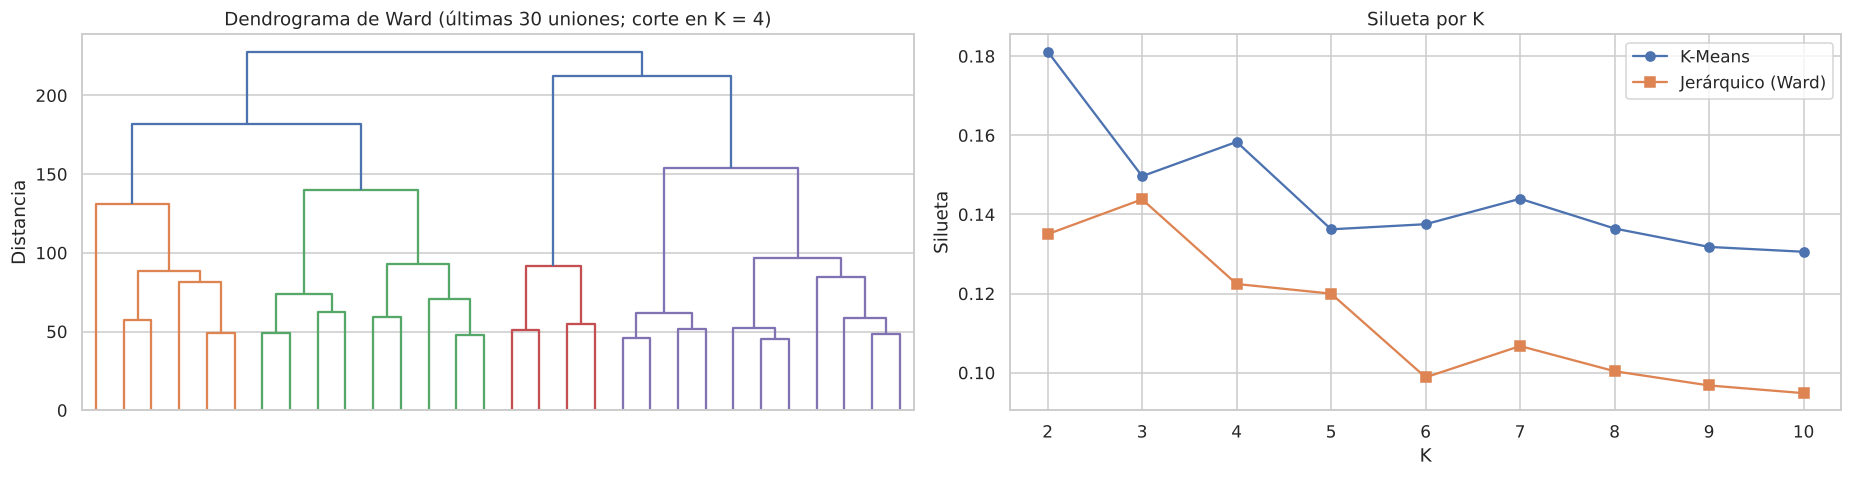

In [13]:
agg_rows = []
for k in ks:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z_tr)
    agg_rows.append({"K": k, "silueta": silhouette_score(Z_tr, lab), "ARI vs PAM50": adjusted_rand_score(pam_tr, lab)})
agg_eval = pd.DataFrame(agg_rows).set_index("K")
display(agg_eval.T)

agg = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit(Z_tr)
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
L = linkage(Z_tr, method="ward")
dendrogram(L, truncate_mode="lastp", p=30, ax=axes[0], color_threshold=L[-(K_FINAL - 1), 2], no_labels=True)
axes[0].set(title=f"Dendrograma de Ward (últimas 30 uniones; corte en K = {K_FINAL})", ylabel="Distancia")
axes[1].plot(km_eval.index, km_eval["silueta"], marker="o", label="K-Means")
axes[1].plot(agg_eval.index, agg_eval["silueta"], marker="s", label="Jerárquico (Ward)")
axes[1].set(title="Silueta por K", xlabel="K", ylabel="Silueta")
axes[1].legend()
plt.tight_layout()
savefig("24_jerarquico")
plt.show()

### 4.3 DBSCAN
DBSCAN agrupa por densidad y marca como ruido los puntos aislados. Su parámetro `eps` se estima con la curva de distancias al k-ésimo vecino (k = `min_samples` = 10).

,clústeres,% ruido,silueta (sin ruido)
eps,,,
6.010,2,67.643,0.147
6.670,2,42.192,0.304
7.530,2,20.946,0.263
8.700,1,8.634,NaN
10.280,1,3.529,NaN
11.460,1,1.877,NaN


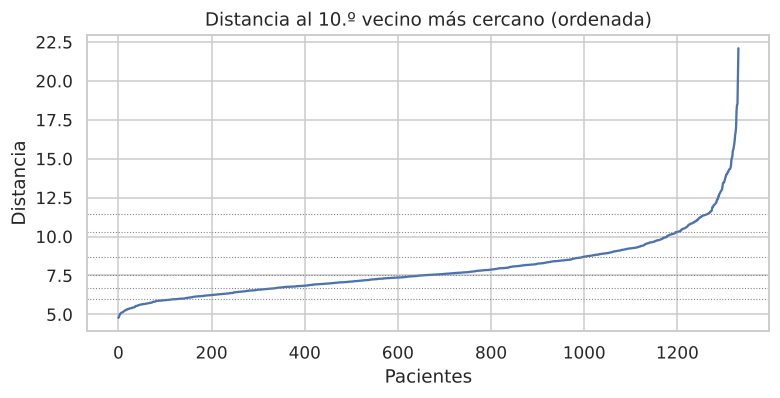

In [14]:
kd = np.sort(NearestNeighbors(n_neighbors=10).fit(Z_tr).kneighbors(Z_tr)[0][:, -1])
eps_grid = np.round(np.percentile(kd, [10, 25, 50, 75, 90, 95]), 2)
db_rows = []
for eps in eps_grid:
    lab = DBSCAN(eps=eps, min_samples=10).fit_predict(Z_tr)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    db_rows.append({"eps": eps, "clústeres": n_cl, "% ruido": 100 * (lab == -1).mean(),
                    "silueta (sin ruido)": silhouette_score(Z_tr[lab != -1], lab[lab != -1]) if n_cl >= 2 else np.nan})
display(pd.DataFrame(db_rows).set_index("eps"))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(kd)
for e in eps_grid:
    ax.axhline(e, color="gray", ls=":", lw=.7)
ax.set(title="Distancia al 10.º vecino más cercano (ordenada)", xlabel="Pacientes", ylabel="Distancia")
plt.show()

### 4.4 Comparación de los algoritmos y estabilidad

In [15]:
km_lab, agg_lab = kmeans.labels_, agg.labels_
# Estabilidad de K-Means: ARI entre ajustes con semillas distintas y sobre submuestras (bootstrap 80 %)
rng = np.random.default_rng(SEED)
stab = []
for b in range(20):
    idx = rng.choice(len(Z_tr), size=int(.8 * len(Z_tr)), replace=False)
    km_b = KMeans(n_clusters=K_FINAL, n_init=10, random_state=b).fit(Z_tr[idx])
    stab.append(adjusted_rand_score(km_lab[idx], km_b.labels_))
comp = pd.DataFrame({
    "silueta": [silhouette_score(Z_tr, km_lab), silhouette_score(Z_tr, agg_lab)],
    "ARI vs PAM50": [adjusted_rand_score(pam_tr, km_lab), adjusted_rand_score(pam_tr, agg_lab)],
    "NMI vs PAM50": [normalized_mutual_info_score(pam_tr, km_lab), normalized_mutual_info_score(pam_tr, agg_lab)],
}, index=[f"K-Means (K = {K_FINAL})", f"Jerárquico Ward (K = {K_FINAL})"])
display(comp)
print(f"Acuerdo entre K-Means y jerárquico (ARI): {adjusted_rand_score(km_lab, agg_lab):.3f}")
print(f"Estabilidad de K-Means en 20 submuestras del 80 % (ARI medio): {np.mean(stab):.3f} ± {np.std(stab):.3f}")

,silueta,ARI vs PAM50,NMI vs PAM50
K-Means (K = 4),0.158,0.209,0.264
Jerárquico Ward (K = 4),0.122,0.184,0.219


Acuerdo entre K-Means y jerárquico (ARI): 0.399
Estabilidad de K-Means en 20 submuestras del 80 % (ARI medio): 0.929 ± 0.037


### 4.5 Perfil e interpretación de los clústeres (K-Means)
Se asigna un clúster a todas las pacientes (las de validación y prueba con `kmeans.predict`, es decir, al centroide más cercano aprendido en entrenamiento) y se describe cada grupo con variables clínicas que **no** se usaron para formarlo.

In [16]:
df = df.copy()
df["cluster"] = kmeans.predict(Z_all)
prof = df.groupby("cluster").agg(
    pacientes=("patient_id", "size"),
    edad_media=("age_at_diagnosis", "mean"),
    NPI_medio=("nottingham_prognostic_index", lambda s: s[df.loc[s.index, "npi_valid"] == 1].mean()),
    grado_3_pct=("neoplasm_histologic_grade", lambda s: 100 * (s == 3).mean()),
    ER_pos_pct=("er_status", lambda s: 100 * (s == "Positive").mean()),
    HER2_pos_pct=("her2_status", lambda s: 100 * (s == "Positive").mean()),
    triple_neg_pct=("triple_negative", lambda s: 100 * s.mean()),
    proliferacion=("proliferation_score", "mean"),
    TP53_mut_pct=("tp53_mut", lambda s: 100 * s.mean()),
    PIK3CA_mut_pct=("pik3ca_mut", lambda s: 100 * s.mean()),
    muerte_por_cancer_pct=("death_from_cancer", lambda s: 100 * (s == "Died of Disease").mean()),
    supervivencia_mediana_meses=("overall_survival_months", "median"),
)
display(prof)
comp_pam = pd.crosstab(df["cluster"], df[config.TARGET_CLASSIFICATION], normalize="index")[CLASS_ORDER] * 100
display(comp_pam.round(1))

# Diferencias entre clústeres: Kruskal-Wallis (cuantitativas) y chi-cuadrado (cualitativas)
tests = {
    "NPI": stats.kruskal(*[g.loc[g.npi_valid == 1, "nottingham_prognostic_index"] for _, g in df.groupby("cluster")]).pvalue,
    "edad": stats.kruskal(*[g["age_at_diagnosis"] for _, g in df.groupby("cluster")]).pvalue,
    "supervivencia (meses)": stats.kruskal(*[g["overall_survival_months"] for _, g in df.groupby("cluster")]).pvalue,
    "muerte por cáncer": stats.chi2_contingency(pd.crosstab(df["cluster"], df["death_from_cancer"] == "Died of Disease"))[1],
    "PAM50": stats.chi2_contingency(pd.crosstab(df["cluster"], df[config.TARGET_CLASSIFICATION]))[1],
}
print("p-valores de diferencias entre clústeres:", {k: f"{v:.1e}" for k, v in tests.items()})

,pacientes,edad_media,NPI_medio,grado_3_pct,ER_pos_pct,HER2_pos_pct,triple_neg_pct,proliferacion,TP53_mut_pct,PIK3CA_mut_pct,muerte_por_cancer_pct,supervivencia_mediana_meses
cluster,,,,,,,,,,,,
0,356,55.356,4.691,90.449,14.045,21.629,64.045,1.028,87.360,20.506,40.730,90.350
1,615,58.980,3.901,34.472,86.179,10.244,8.455,-0.553,22.114,54.959,28.130,123.333
2,149,62.696,4.041,50.336,77.181,20.134,10.067,0.162,39.597,40.940,36.242,128.100
3,783,65.054,3.992,40.613,97.573,8.429,0.383,-0.064,19.413,41.252,31.928,116.233


pam50_+_claudin-low_subtype,LumA,LumB,Her2,Basal,claudin-low,Normal
cluster,,,,,,
0,0.800,3.700,21.600,47.500,24.700,1.700
1,47.000,10.900,6.000,2.000,17.400,16.400
2,31.500,12.800,36.200,10.100,0.700,7.400
3,43.400,46.200,6.600,0.400,0.300,2.800


p-valores de diferencias entre clústeres: {'NPI': '8.9e-29', 'edad': '8.2e-36', 'supervivencia (meses)': '1.2e-06', 'muerte por cáncer': '6.0e-04', 'PAM50': '3.0e-299'}


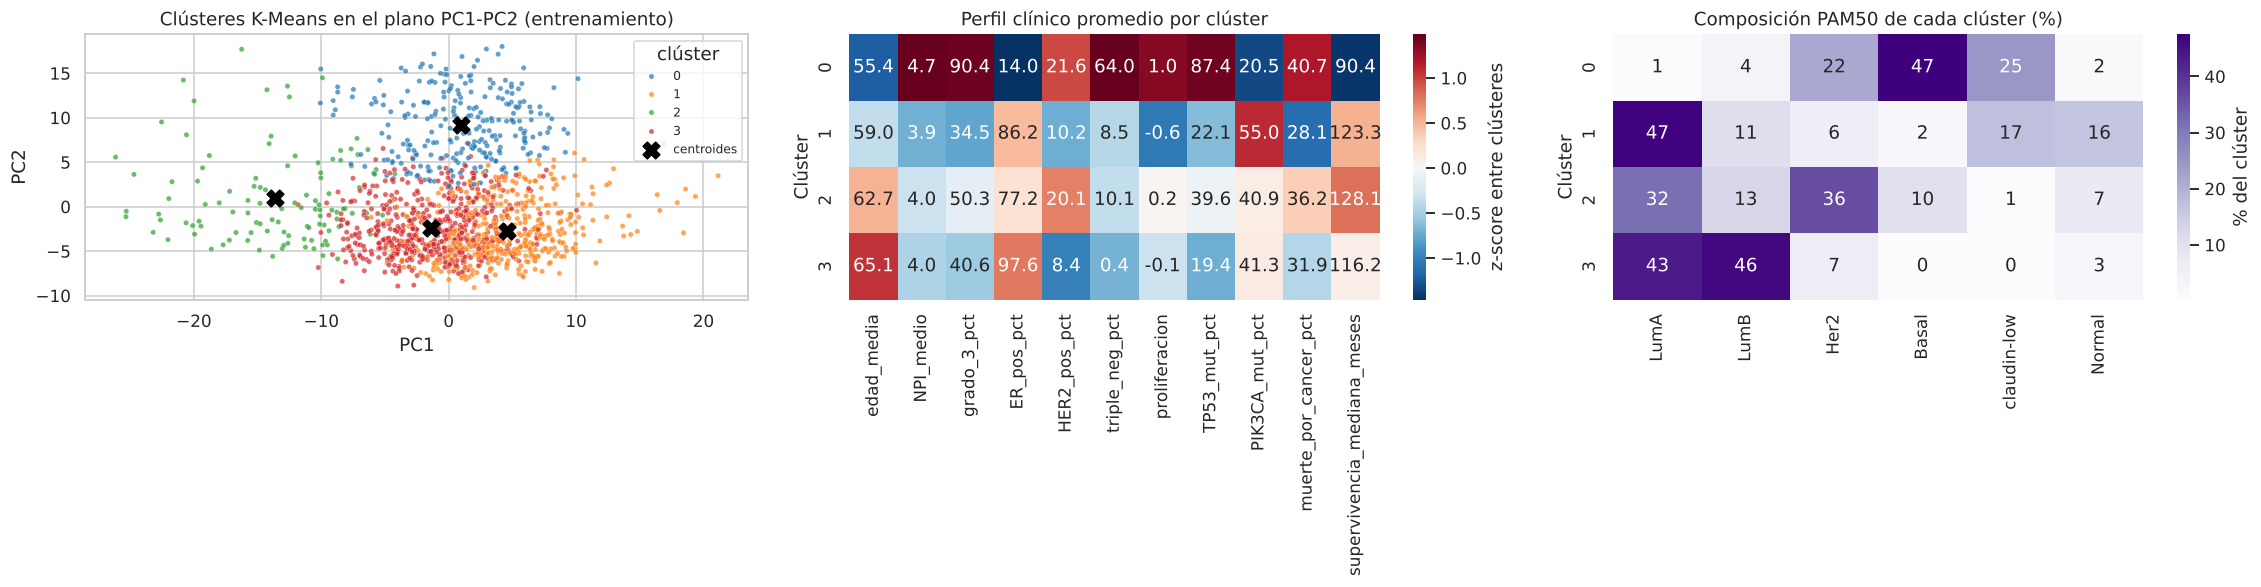

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
pal = sns.color_palette("tab10", K_FINAL)
sns.scatterplot(x=Z_all[is_tr, 0], y=Z_all[is_tr, 1], hue=km_lab, palette=pal, s=12, alpha=.7, ax=axes[0])
cent = kmeans.cluster_centers_
axes[0].scatter(cent[:, 0], cent[:, 1], c="black", marker="X", s=120, label="centroides")
axes[0].set(title=f"Clústeres K-Means en el plano PC1-PC2 (entrenamiento)", xlabel="PC1", ylabel="PC2")
axes[0].legend(title="clúster", fontsize=8)
z = prof.drop(columns=["pacientes"])
sns.heatmap((z - z.mean()) / z.std(), annot=z.round(1), fmt="", cmap="RdBu_r", center=0, ax=axes[1],
            cbar_kws={"label": "z-score entre clústeres"})
axes[1].set(title="Perfil clínico promedio por clúster", xlabel="", ylabel="Clúster")
sns.heatmap(comp_pam, annot=True, fmt=".0f", cmap="Purples", ax=axes[2], cbar_kws={"label": "% del clúster"})
axes[2].set(title="Composición PAM50 de cada clúster (%)", xlabel="", ylabel="Clúster")
plt.tight_layout()
savefig("25_perfiles_clusteres")
plt.show()

**Interpretación de los clústeres.** Los cuatro grupos se formaron solo con expresión génica, pero difieren de manera significativa en variables clínicas que no participaron en su construcción: NPI, edad, meses de supervivencia, muerte por cáncer y subtipo PAM50 (todos con p < 0,001).

| Clúster | Nombre propuesto | Rasgos distintivos |
|---|---|---|
| 0 | **Agresivo ER negativo (basal / claudin-low)** | 14 % ER+, 64 % triple negativo, 90 % grado 3, mayor proliferación, TP53 mutado en el 87 %; las pacientes más jóvenes (55 años), el NPI más alto (4,7), la mayor mortalidad por cáncer (41 %) y la menor supervivencia mediana (90 meses). Agrupa casi todos los Basal y gran parte de los claudin-low. |
| 1 | **Luminal de baja proliferación** | 86 % ER+, la proliferación más baja, PIK3CA mutado en el 55 %; NPI de 3,9 y la menor mortalidad por cáncer (28 %). Predominan Luminal A, Normal-like y una fracción de claudin-low ER+. |
| 2 | **Intermedio con perfil HER2 (con cautela)** | Grupo pequeño (8 %), con la mayor proporción de tumores HER2-enriquecidos según PAM50 (36 %) y HER2+ clínico (20 %), proliferación intermedia y mortalidad por cáncer del 36 %. **Nota de la actividad 6:** el 83 % de este grupo proviene de la cohorte C3, lo que indica un probable efecto de lote; su interpretación biológica no es confiable (ver cuaderno 06, sección 7.1). |
| 3 | **Luminal clásico (A/B)** | 98 % ER+, prácticamente sin triple negativos, las pacientes de mayor edad (65 años) y una mezcla equilibrada de Luminal A y Luminal B; riesgo intermedio (NPI 4,0; 32 % de mortalidad por cáncer). |

**Valor práctico.** La segmentación ordena a las pacientes en un eje de agresividad biológica (proliferación, receptores y TP53) que se asocia con el pronóstico (mortalidad por cáncer y supervivencia). El clúster 0 concentra el mayor riesgo y el 1 reúne tumores luminales de mejor pronóstico. Si esa asociación se mantiene al ajustar por NPI (algo que este análisis no prueba), podría servir para explorar el desescalamiento de tratamientos. Esta segmentación alimentará el módulo de clustering del dashboard.

## 5. Modelos guardados y conclusiones

In [18]:
FILE_NAMES = {"Ridge": "ridge", "ElasticNet / Lasso": "elasticnet", "Random Forest": "random_forest",
              "XGBoost": "xgboost", "Logística regularizada (L2)": "logistica_l2", "SVM": "svm"}
for name, mdl in reg_models.items():
    joblib.dump(mdl, config.MODELS_DIR / f"reg_{FILE_NAMES[name]}.joblib", compress=3)
for name, mdl in clf_models.items():
    joblib.dump(mdl, config.MODELS_DIR / f"clf_{FILE_NAMES[name]}.joblib", compress=3)
joblib.dump({"scaler": scaler_g, "pca": pca, "kmeans": kmeans, "genes": genes, "n_pc": N_PC, "k": K_FINAL},
            config.MODELS_DIR / "clustering_kmeans.joblib", compress=3)
joblib.dump(le, config.MODELS_DIR / "label_encoder_pam50.joblib")
df[["patient_id", "split", "cluster"]].to_csv(config.DATA_PROCESSED / "clusters.csv", index=False)

reg_table.drop(columns="_rmse_cv").to_csv(config.METRICS_DIR / "act5_regresion.csv", encoding="utf-8-sig")
clf_table.drop(columns="_f1_cv").to_csv(config.METRICS_DIR / "act5_clasificacion.csv", encoding="utf-8-sig")
pd.concat([km_eval.add_prefix("kmeans_"), agg_eval.add_prefix("ward_")], axis=1).to_csv(config.METRICS_DIR / "act5_clustering.csv")
pd.DataFrame(reg_results + clf_results).to_json(config.METRICS_DIR / "act5_hiperparametros.json", orient="records",
                                                force_ascii=False, indent=1, default_handler=str)
rmtree(CACHE, ignore_errors=True)
for p in sorted(config.MODELS_DIR.glob("*.joblib")):
    print(f"{p.relative_to(config.ROOT_DIR)}  ({p.stat().st_size / 1e6:.1f} MB)")

models/clf_logistica_l2.joblib  (0.1 MB)
models/clf_random_forest.joblib  (3.9 MB)
models/clf_svm.joblib  (4.4 MB)
models/clf_xgboost.joblib  (0.3 MB)
models/clustering_kmeans.joblib  (0.1 MB)
models/label_encoder_pam50.joblib  (0.0 MB)
models/reg_elasticnet.joblib  (0.0 MB)
models/reg_random_forest.joblib  (1.6 MB)
models/reg_ridge.joblib  (0.0 MB)
models/reg_xgboost.joblib  (0.2 MB)


### Conclusiones de la actividad 5

1. **Regresión (NPI).** Los cuatro modelos superan al modelo base: RMSE de CV entre 0,947 y 0,956, frente a 0,995, y R² entre 0,217 y 0,233, frente a 0,153. XGBoost tiene el menor RMSE de CV, pero Ridge (α ≈ 3.162) queda a menos de un error estándar y, por la **regla de un error estándar**, es el líder provisional. Además se sobreajusta mucho menos (brecha de R² de 0,13 frente a 0,58) y rinde mejor en validación (R² = 0,209; RMSE = 0,972). Con ese R² en validación ya se cumple la meta SMART de R² ≥ 0,20, pendiente de confirmar en prueba. ElasticNet conserva 76 de 588 variables, y las de mayor peso reflejan el eje proliferación frente a diferenciación luminal: NCOA3, GSK3B y AURKA suben el NPI; RUNX1, BCL2 e IGF1R lo bajan.
2. **Clasificación (PAM50).** Los cuatro modelos superan al modelo base en CV: F1 macro entre 0,722 y 0,746, frente a 0,698. XGBoost obtiene el mayor F1 de CV (0,746 ± 0,018) y el mejor desempeño en validación (F1 macro = 0,787; exactitud = 0,817; AUC-ROC = 0,969). SVM con kernel RBF queda dentro de un error estándar (0,741). Regularizar la logística (C = 0,01) reduce la brecha de sobreajuste de 0,30 a 0,22, pero **ningún modelo cumple todavía la meta de brecha menor que 0,15** (0,22 a 0,27). Esto se abordará en la actividad 6, junto con la evaluación en prueba. Normal-like sigue siendo la clase más difícil: alrededor de un tercio se confunde con Luminal A, algo coherente con su definición, que depende de la proporción de tejido mamario normal en la muestra.
3. **Clustering.** Con 10 componentes principales (35,8 % de la varianza, elegidas por el codo), K-Means con K = 4 (codo y máximo local de la silueta) produce grupos muy estables (ARI = 0,93 en submuestras) y con significado clínico, aunque con silueta baja (0,158), típica de datos de expresión continuos. El clustering jerárquico de Ward es menos compacto (silueta = 0,122) y coincide solo moderadamente con K-Means (ARI = 0,40). DBSCAN no es adecuado: según `eps`, deja entre el 21 % y el 68 % de las pacientes como ruido o las agrupa a todas en un solo clúster. Esto indica que los datos no tienen regiones de densidad bien separadas.
4. **Artefactos.** Los modelos ajustados están en `models/` y las métricas e hiperparámetros en `reports/metrics/act5_*`; la asignación de clústeres de todas las pacientes está en `data/processed/clusters.csv`.

**Siguiente paso (actividad 6):** comparar los modelos en el conjunto de prueba con pruebas estadísticas, atacar la brecha de sobreajuste en clasificación, interpretar los modelos con SHAP e importancia de variables y elegir los modelos finales para el dashboard.